# Phase 2 – Part A: Unsupervised Learning
**SWE485 – Group 4 – University Student Retention & Advisory Dashboard**

| Section | Owner |
|---|---|
| K-Means: rationale, data preparation, choosing *k*, implementation, cluster profiles, saved model, Random Forest + cluster-feature test | Najd Al Ghanim |
| Agglomerative clustering: rationale, choosing *k*, algorithm comparison (Silhouette, Davies-Bouldin, WCSS, BCubed), all cluster visualizations, Integration Strategy, Challenges & Limitations | Yusra Al Helal |

**Agreed setting:** `K = 3` clusters for both algorithms (justified in Section 3.2).

> **Note for Najd:** add your cells in the placeholder boxes below. Yusra's cells already run on their own
> (they load the data and fit K-Means with `K = 3`), so nothing in them needs to change as long as `K = 3`.

## 0. Setup (shared)
Imports, paths and data loading used by all sections.

In [1]:
# ============================================================
# Setup: imports, paths, data
# ============================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
K = 3   # must match the K chosen in the K-Means section

# Works whether the notebook is run from the repo root or from Unsupervised_Learning/
ROOT = Path(".") if Path("Dataset").exists() else Path("..")
PLOTS = ROOT / "Unsupervised_Learning" / "plots"
OUTPUTS = ROOT / "Unsupervised_Learning" / "outputs"
PLOTS.mkdir(parents=True, exist_ok=True)
OUTPUTS.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "Dataset" / "preprocessed_data.csv")
raw = pd.read_csv(ROOT / "Dataset" / "data.csv", sep=None, engine="python")
raw.columns = [c.strip() for c in raw.columns]

# Clustering input: remove the class label (and the split marker). Features are already
# encoded and scaled in Phase 1, so no extra scaling is applied here.
X = df.drop(columns=["Target", "split"]).values
feature_names = df.drop(columns=["Target", "split"]).columns

# Ground truth is kept ONLY for external validation (BCubed) and for profiling.
TARGET_NAMES = {0: "Dropout", 1: "Enrolled", 2: "Graduate"}
y_true = df["Target"].map(TARGET_NAMES).values

# Rows of preprocessed_data.csv are in the same order as data.csv
assert (raw["Target"].values == y_true).all()
print("Clustering matrix:", X.shape)

Clustering matrix: (4424, 102)


## 1. Clustering Rationale & Algorithm Selection

> **[Najd – section to be added here]** 1.1 Algorithm 1 – K-Means: why it fits our data
>
> - Dataset size and feature types
> - Expected (spherical) cluster shape
> - Scalability and interpretability

### 1.2 Algorithm 2 – Agglomerative Clustering (Ward linkage)

K-Means is the first algorithm. For the second one we considered three options:

| Option | Fit for our data | Decision |
|---|---|---|
| **Agglomerative (Ward)** | 4,424 rows is small enough for hierarchical clustering (O(n²) memory ≈ 150 MB). Deterministic (no random initialisation). The dendrogram shows the cluster hierarchy and helps choose *k*. Ward minimises within-cluster variance, so its WCSS is directly comparable with K-Means. | **Selected** |
| Gaussian Mixture (GMM) | Assumes each cluster is a Gaussian. Most of our 102 features are 0/1 one-hot columns, which breaks this assumption, and full covariance in 102 dimensions is unstable. | Rejected (checked below) |
| DBSCAN | Needs a meaningful density/distance. In 102 mostly-binary dimensions distances become similar, so choosing `eps` is unreliable and most points end up as noise or one cluster. | Rejected |

**Expected cluster shape:** Ward builds compact, roughly spherical groups (like K-Means), but it does it bottom-up, so it can follow
the hierarchy of the data instead of depending on random centroids. **Interpretability:** high – each merge can be read from the dendrogram.
**Scalability:** limited (O(n²)), acceptable for our dataset but a known limitation for larger cohorts.

The quick check below supports rejecting GMM: its silhouette is much lower than both distance-based methods for every *k*.

In [2]:
# Quick evidence for the algorithm choice (GMM uses diagonal covariance to stay numerically stable)
rows = []
for k in range(2, 7):
    ag = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    gm = GaussianMixture(n_components=k, covariance_type="diag", random_state=RANDOM_STATE, n_init=3).fit(X).predict(X)
    rows.append({"k": k,
                 "Agglomerative silhouette": silhouette_score(X, ag),
                 "GMM silhouette": silhouette_score(X, gm)})
display(pd.DataFrame(rows).round(3).set_index("k"))

,Agglomerative silhouette,GMM silhouette
k,,
2,0.276,0.072
3,0.195,0.103
4,0.095,0.074
5,0.103,0.041
6,0.078,0.053


## 2. Data Preparation (target removal, feature scaling)

> **[Najd – section to be added here]** Data preparation
>
> - Explain removal of `Target` and `split` (done in the Setup cell)
> - Explain that features were already encoded and scaled in Phase 1, so no re-scaling is needed

## 3. Cluster Determination & Implementation

> **[Najd – section to be added here]** 3.1 K-Means: choosing k
>
> - Elbow plot (WCSS vs k) and silhouette vs k
> - Final K-Means fit with `K = 3`

### 3.2 Agglomerative clustering: choosing k

We use two complementary methods:
1. **Silhouette and Davies-Bouldin for k = 2…8** (higher silhouette and lower DBI are better).
2. **Dendrogram (Ward)** – a large vertical jump before a merge means two distinct groups are being forced together.

,Silhouette,Davies-Bouldin,Smallest cluster
k,,,
2,0.276,1.636,320
3,0.195,2.084,320
4,0.095,2.292,320
5,0.103,2.035,40
6,0.078,2.473,40
7,0.078,2.426,40
8,0.060,2.430,40


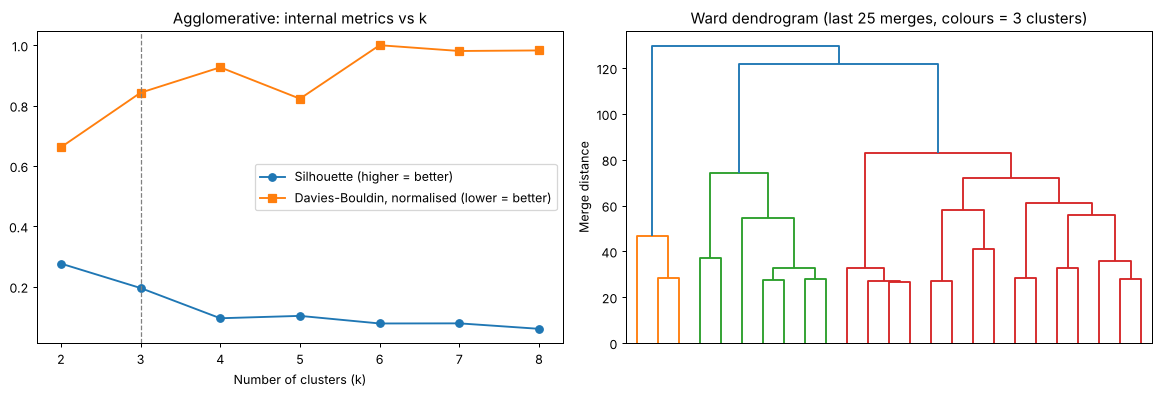

In [3]:
k_rows = []
for k in range(2, 9):
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    k_rows.append({"k": k,
                   "Silhouette": silhouette_score(X, labels),
                   "Davies-Bouldin": davies_bouldin_score(X, labels),
                   "Smallest cluster": np.bincount(labels).min()})
k_table = pd.DataFrame(k_rows).set_index("k")
display(k_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(k_table.index, k_table["Silhouette"], marker="o", label="Silhouette (higher = better)")
axes[0].plot(k_table.index, k_table["Davies-Bouldin"] / k_table["Davies-Bouldin"].max(), marker="s",
             label="Davies-Bouldin, normalised (lower = better)")
axes[0].axvline(K, color="grey", ls="--", lw=1)
axes[0].set_xlabel("Number of clusters (k)"); axes[0].set_title("Agglomerative: internal metrics vs k"); axes[0].legend()

Z = linkage(X, method="ward")
dendrogram(Z, truncate_mode="lastp", p=25, ax=axes[1], no_labels=True, color_threshold=Z[-K + 1, 2])
axes[1].set_title(f"Ward dendrogram (last 25 merges, colours = {K} clusters)")
axes[1].set_ylabel("Merge distance")
plt.tight_layout(); plt.savefig(PLOTS / "agglomerative_k_selection.png", dpi=150); plt.show()

**Choice: k = 3.**
- k = 2 has the highest silhouette, but it only separates a small group of ~320 students from everyone else, which is not useful for advising.
- k = 3 keeps almost the same silhouette (≈0.20) and adds a clearly meaningful group: students with almost no passed units in the 1st semester (≈80% dropout, see profiles below).
- From k = 4 the silhouette drops sharply (≈0.10) and the new splits do not change dropout rates, so they add complexity without decision value.
- In the dendrogram the last two merges are much taller than the rest, which also supports 2–3 clusters.

Both algorithms are therefore compared at the same `K = 3`.

## 4. Evaluation Metrics & Visualizations

### 4.1 Comparison of the two algorithms

Metrics:
- **Silhouette** (−1 to 1, higher = better separated)
- **Davies-Bouldin Index** (≥ 0, lower = better)
- **WCSS** – total within-cluster sum of squares (lower = more compact; computed the same way for both algorithms)
- **BCubed Precision / Recall / F1** against the true outcome (Dropout / Enrolled / Graduate). This is external validation only; the label was **not** used for clustering.

In [4]:
def wcss(X, labels):
    # Total within-cluster sum of squares, computed identically for any clustering
    return sum(((X[labels == c] - X[labels == c].mean(axis=0)) ** 2).sum() for c in np.unique(labels))

def bcubed(labels, truth):
    # BCubed precision/recall/F1 using the cluster-by-class contingency table
    ct = pd.crosstab(labels, truth).values.astype(float)
    n = ct.sum()
    precision = (ct ** 2 / ct.sum(axis=1, keepdims=True)).sum() / n
    recall = (ct ** 2 / ct.sum(axis=0, keepdims=True)).sum() / n
    return precision, recall, 2 * precision * recall / (precision + recall)

kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
agglo = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)
labels = {"K-Means": kmeans.labels_, "Agglomerative (Ward)": agglo.labels_}

comparison = []
for name, lab in labels.items():
    p, r, f = bcubed(lab, y_true)
    comparison.append({"Algorithm": name,
                       "Silhouette ↑": silhouette_score(X, lab),
                       "Davies-Bouldin ↓": davies_bouldin_score(X, lab),
                       "WCSS ↓": wcss(X, lab),
                       "BCubed Precision ↑": p, "BCubed Recall ↑": r, "BCubed F1 ↑": f,
                       "Cluster sizes": sorted(np.bincount(lab).tolist(), reverse=True)})
comparison = pd.DataFrame(comparison).set_index("Algorithm")
comparison.round(3).to_csv(OUTPUTS / "clustering_comparison.csv")
display(comparison.round(3))

print("Adjusted Rand Index between the two algorithms:",
      round(adjusted_rand_score(labels["K-Means"], labels["Agglomerative (Ward)"]), 3))

Adjusted Rand Index between the two algorithms: 0.946


,Silhouette ↑,Davies-Bouldin ↓,WCSS ↓,BCubed Precision ↑,BCubed Recall ↑,BCubed F1 ↑,Cluster sizes
Algorithm,,,,,,,
K-Means,0.192,2.009,70788.632,0.461,0.678,0.548,"[3409, 724, 291]"
Agglomerative (Ward),0.195,2.084,71568.212,0.459,0.666,0.543,"[3374, 730, 320]"


**Interpretation of the comparison**
- **Internal metrics are almost tied.** Silhouette, Davies-Bouldin and WCSS differ only slightly. K-Means has a marginally lower WCSS,
  which is expected because WCSS is exactly what K-Means optimises.
- **The two algorithms find essentially the same structure** – the Adjusted Rand Index is very high, so the clusters are not an artefact of one method.
- **The absolute silhouette is modest (≈0.2).** This is typical for 102 dimensions where most columns are one-hot: distances become similar,
  so clusters overlap even when they are meaningful.
- **BCubed:** precision is moderate and recall is high-ish because one large cluster contains most Graduates *and* most Enrolled students.
  Clusters do not reproduce the three outcomes – which is expected: they group students by *profile*, not by outcome.
  The one cluster that does align with an outcome is the "no academic progress" group, which is mostly Dropout.

**Practical winner: K-Means.** With equal quality, K-Means is preferred for the system because it has a `predict()` method
and can assign a *new* student to a cluster in the dashboard. Agglomerative clustering cannot label new points without refitting.
Agglomerative is kept as a validation method that confirms the K-Means structure.

### 4.2 2D projections (PCA and t-SNE)
PCA is linear and shows global structure; t-SNE preserves local neighbourhoods and usually separates groups more visibly.

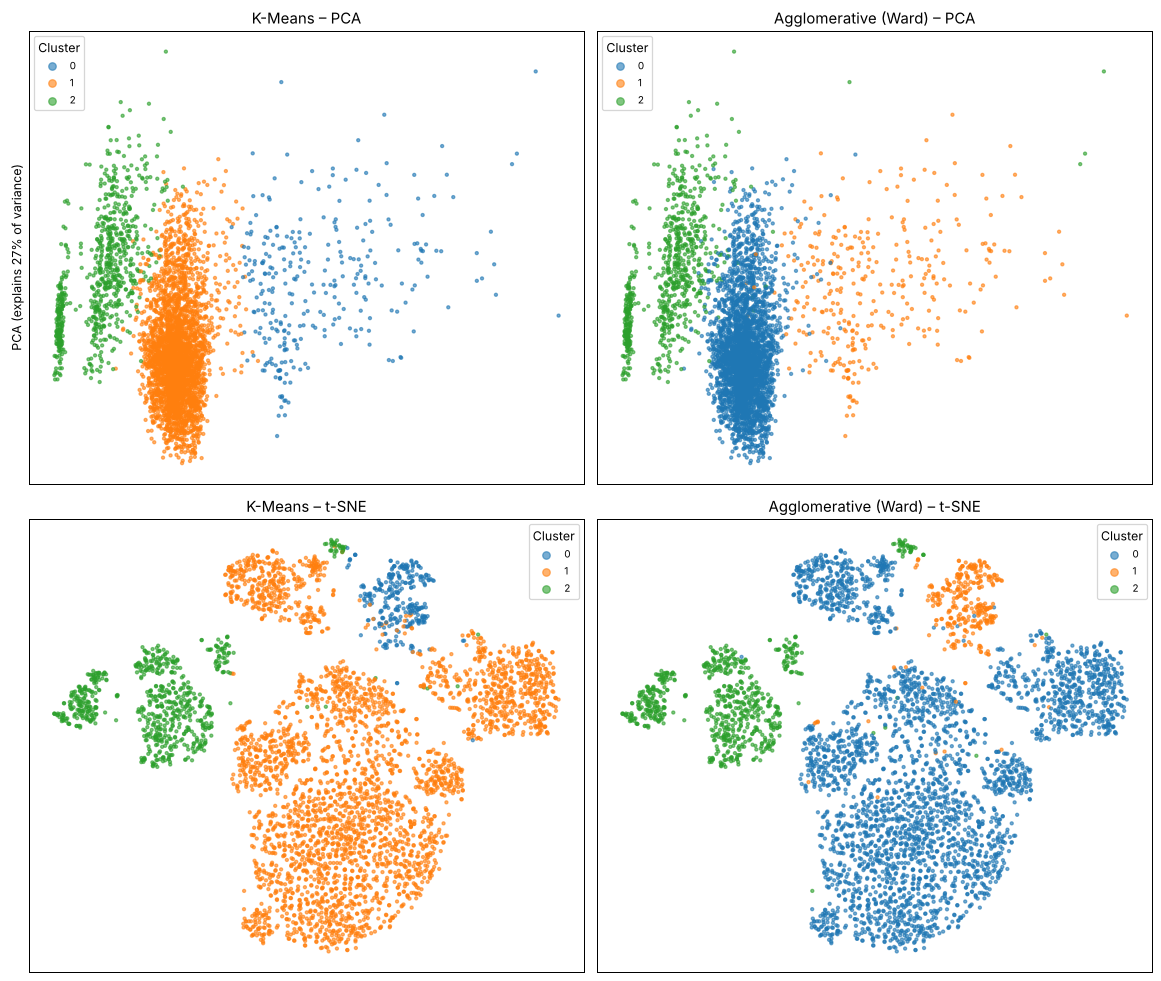

In [5]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
X_tsne = TSNE(n_components=2, perplexity=40, init="pca", random_state=RANDOM_STATE).fit_transform(X)

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for col, (name, lab) in enumerate(labels.items()):
    for row, (proj, title) in enumerate([(X_pca, "PCA"), (X_tsne, "t-SNE")]):
        ax = axes[row, col]
        sc = ax.scatter(proj[:, 0], proj[:, 1], c=lab, cmap="tab10", s=6, alpha=0.6, vmin=0, vmax=9)
        ax.set_title(f"{name} – {title}")
        ax.set_xticks([]); ax.set_yticks([])
        ax.legend(*sc.legend_elements(), title="Cluster", loc="best", fontsize=8)
axes[0, 0].set_ylabel(f"PCA (explains {pca.explained_variance_ratio_.sum():.0%} of variance)")
plt.tight_layout(); plt.savefig(PLOTS / "clusters_pca_tsne.png", dpi=150); plt.show()

### 4.3 Cluster size distribution, and outcome mix inside each cluster

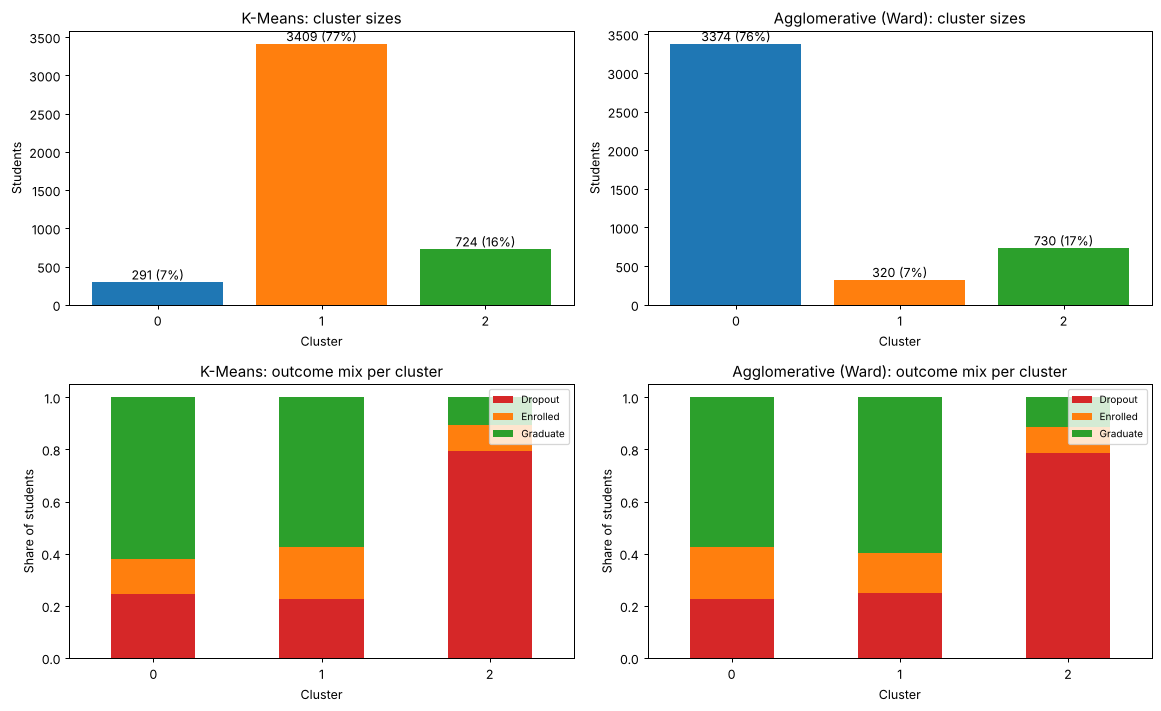

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for col, (name, lab) in enumerate(labels.items()):
    sizes = pd.Series(lab).value_counts().sort_index()
    axes[0, col].bar(sizes.index.astype(str), sizes.values, color=sns.color_palette("tab10", K))
    for i, v in enumerate(sizes.values):
        axes[0, col].text(i, v, f"{v} ({v / len(lab):.0%})", ha="center", va="bottom")
    axes[0, col].set_title(f"{name}: cluster sizes"); axes[0, col].set_xlabel("Cluster"); axes[0, col].set_ylabel("Students")

    mix = pd.crosstab(lab, y_true, normalize="index")[["Dropout", "Enrolled", "Graduate"]]
    mix.plot(kind="bar", stacked=True, ax=axes[1, col], color=["#d62728", "#ff7f0e", "#2ca02c"], rot=0)
    axes[1, col].set_title(f"{name}: outcome mix per cluster"); axes[1, col].set_xlabel("Cluster")
    axes[1, col].set_ylabel("Share of students"); axes[1, col].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(PLOTS / "cluster_sizes_and_outcomes.png", dpi=150); plt.show()

### 4.4 Feature means per cluster and feature importance per cluster
Means are shown in **original units** (from `data.csv`) so they are readable. "Importance" for a cluster is how far the cluster's mean is from the
overall mean, measured in standard deviations: large positive/negative values are the features that define that cluster.

,0,1,2
Age at enrollment,22.16,29.09,25.80
Admission grade,126.91,128.03,126.85
Curricular units 1st sem (credited),0.17,7.92,0.06
Curricular units 1st sem (enrolled),6.12,12.50,4.25
Curricular units 1st sem (approved),5.11,10.94,0.10
Curricular units 1st sem (grade),12.71,12.57,0.22
Tuition fees up to date,0.92,0.89,0.71
Debtor,0.09,0.16,0.18
Scholarship holder,0.29,0.11,0.10
Daytime/evening attendance,0.91,0.71,0.86


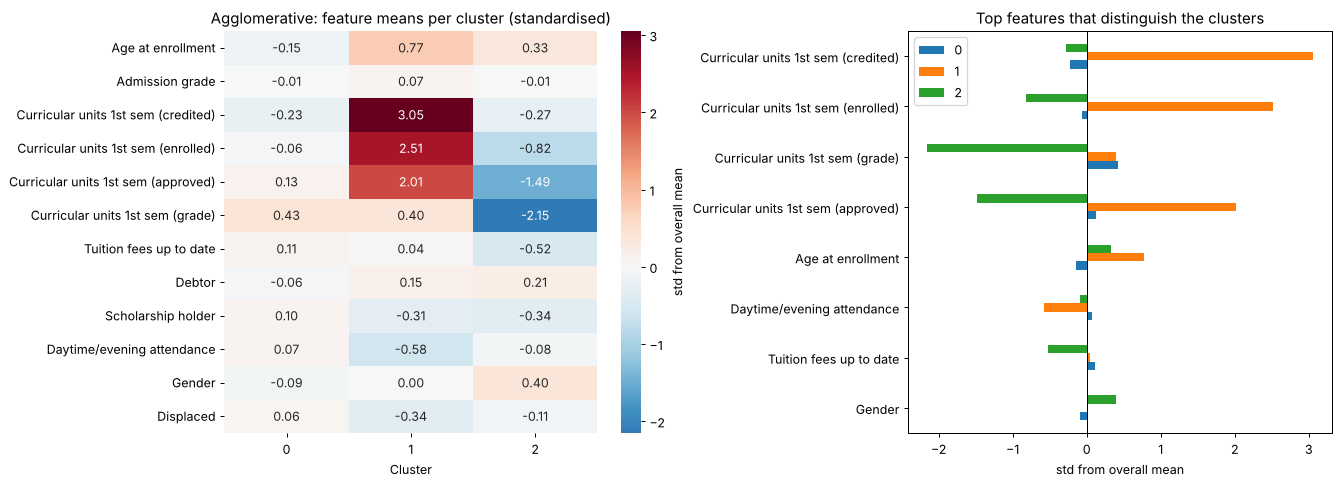

In [7]:
profile_cols = ["Age at enrollment", "Admission grade",
                "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
                "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
                "Tuition fees up to date", "Debtor", "Scholarship holder",
                "Daytime/evening attendance", "Gender", "Displaced"]

lab = labels["Agglomerative (Ward)"]
means = raw[profile_cols].groupby(lab).mean()
means["Students"] = np.bincount(lab)
means = means.join(pd.crosstab(lab, y_true, normalize="index").add_suffix(" rate"))
display(means.round(2).T)

# Standardised difference from the overall mean (feature importance per cluster)
z = (raw[profile_cols].groupby(lab).mean() - raw[profile_cols].mean()) / raw[profile_cols].std()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(z.T, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0], cbar_kws={"label": "std from overall mean"})
axes[0].set_title("Agglomerative: feature means per cluster (standardised)"); axes[0].set_xlabel("Cluster")

top = z.abs().max().sort_values(ascending=True).tail(8).index
z[top].T.plot(kind="barh", ax=axes[1], color=sns.color_palette("tab10", K))
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Top features that distinguish the clusters"); axes[1].set_xlabel("std from overall mean")
plt.tight_layout(); plt.savefig(PLOTS / "cluster_feature_importance.png", dpi=150); plt.show()

pd.DataFrame({"agglomerative_cluster": lab, "kmeans_cluster": labels["K-Means"]}).to_csv(
    OUTPUTS / "cluster_labels_both_algorithms.csv", index_label="row_id")

## 5. Cluster Interpretation & Profiles

> **[Najd – section to be added here]** 5.1 K-Means cluster profiles
>
> - Profile of each K-Means cluster in student terms
> - Save `Unsupervised_Learning/outputs/cluster_profiles.json` and `cluster_model.joblib`

### 5.2 Agglomerative cluster profiles

**Agglomerative cluster profiles** (cluster numbers may differ from K-Means; the groups are the same):

| Profile | Who they are | Outcome | Advisory meaning |
|---|---|---|---|
| **Regular on-track students** (largest, ~76%) | Young (~22), day-time, full normal load, pass most units, grade ≈12.7/20 | ~57% Graduate, ~23% Dropout | Standard monitoring; the RF model is needed here because the cluster alone cannot tell who will drop out |
| **Mature transfer / credited students** (~7%) | Older (~29), many units credited from previous studies, high enrolled and approved units, more evening classes | ~60% Graduate | Different needs (work/family); flexible scheduling rather than academic remediation |
| **No-progress students** (~16%) | Enrolled but passed almost no units, grade ≈0, more fee arrears and debtors | **~80% Dropout** | Highest priority for immediate outreach, financial-aid referral and academic recovery plans |

## 6. Integration Strategy – how the clusters enhance the system

1. **Deployed clustering model = K-Means.** It reaches the same structure as Agglomerative clustering (high ARI) and can assign a new
   student with `predict()`. It is saved as `Unsupervised_Learning/outputs/cluster_model.joblib` together with
   `cluster_profiles.json` (name, description, dropout rate of each cluster).
2. **Dashboard – cohort segmentation.** The KPI page shows retention per cluster, so a dean sees immediately that one segment
   (no-progress students) carries most of the dropout risk.
3. **Dashboard – student simulator.** After the Random Forest predicts the outcome, the simulated student is also assigned to a cluster,
   and the cluster profile is shown next to the prediction. Moving the GPA/attendance sliders can move the student between clusters,
   which makes the "trajectory" visible.
4. **Generative AI – personalisation.** The cluster profile is passed into the prompt (`{cluster_profile}` placeholder), so the counseling
   outreach summary is tailored (e.g., flexible-schedule advice for mature students, financial-aid referral for the no-progress group).
5. **Rule-based early alert.** Membership in the no-progress cluster (~80% dropout) is a simple, explainable flag that complements the
   Random Forest probabilities.
6. **Cluster as a model feature.** Adding the cluster label to the Random Forest is tested in Section 6.1. Because the clusters are built
   mostly from the same academic features the forest already uses, a large improvement is not expected; the clusters' main value is
   segmentation and explanation, not raw accuracy.

> **[Najd – section to be added here]** 6.1 Integration test: Random Forest with and without the cluster label
>
> - Macro F1 and Enrolled F1, before vs after adding the cluster feature
> - Fit the clusters on the training rows only to avoid leakage

## 7. Challenges & Limitations

- **High-dimensional, mostly binary data.** 102 features, most of them one-hot. Distances become less informative, which explains the modest
  silhouette (≈0.2) for both algorithms.
- **Clusters do not separate "Enrolled".** Enrolled students sit inside the large regular cluster with future graduates. This mirrors the
  Phase 1 finding that Enrolled is the hardest class.
- **Clusters are dominated by academic features.** Many one-hot categories (course, parents' occupation) add noise rather than structure.
  Feature selection or weighting before clustering could give finer segments (future work).
- **Agglomerative scalability.** O(n²) memory and no `predict()` for new students; fine for 4,424 records but not for a live system.
- **Choice of k is a trade-off.** k = 2 scores best on silhouette but is not useful for advising; we chose k = 3 for interpretability.
- **Associations, not causes.** A cluster with high dropout identifies who needs support; it does not prove why students drop out.
- **Ethics.** Cluster labels must not become fixed "labels" for students. They are used to prioritise support, never to restrict opportunities.